# Uso de ferramentas de IA e satisfação no trabalho de desenvolvedores

**MCEQ 12576 · PUC-Campinas · Projeto Final**
Equipe: Gabriel Angeli Capovilla e Henrique Della Guardia de Azevedo Martins

Este notebook reproduz todos os números do artigo, do dado bruto ao resultado. Rode as células em ordem (*Run All*).

- **Base:** Stack Overflow Annual Developer Survey 2025 (49.019 respostas, 177 países). Licença ODbL 1.0. Dados: https://survey.stackoverflow.co/
- **Protocolo:** `docs/protocolo.pdf`. A análise confirmatória (seções 1 a 6) segue o protocolo; a seção 7 é **exploratória**.
- **Tipo de estudo:** observacional (questionário). Os resultados indicam **associação**, não causa.

## 0. Configuração

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

RAIZ = Path('.')
BRUTOS = RAIZ / 'dados' / 'brutos'
LIMPOS = RAIZ / 'dados' / 'limpos'
FIGURAS = RAIZ / 'figuras'
LIMPOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

ALFA = 0.05  # fixado no protocolo

# Os 5 níveis da VI, na ordem do questionário (do uso mais frequente ao não uso)
GRUPOS = {
    'Yes, I use AI tools daily': 'Diário',
    'Yes, I use AI tools weekly': 'Semanal',
    'Yes, I use AI tools monthly or infrequently': 'Mensal/raro',
    'No, but I plan to soon': 'Não usa, pretende',
    "No, and I don't plan to": 'Não usa, não pretende',
}
ORDEM = list(GRUPOS.values())
PROFISSIONAL = 'I am a developer by profession'
pd.set_option('display.precision', 3)

## 1. Carregar o dado bruto

O arquivo bruto **nunca é editado**. Uma linha = um respondente. Lemos só as colunas usadas na análise.

In [2]:
arquivos = [p for p in [BRUTOS / 'survey_results_public.csv', BRUTOS / 'results.csv'] if p.exists()]
assert arquivos, 'Coloque o CSV da pesquisa em dados/brutos/ (survey_results_public.csv ou results.csv)'
CSV = arquivos[0]

COLUNAS = ['ResponseId', 'MainBranch', 'Country', 'AISelect', 'JobSat', 'WorkExp', 'AISent']
cabecalho = pd.read_csv(CSV, nrows=0).columns
usar = [c for c in COLUNAS if c in cabecalho]
bruto = pd.read_csv(CSV, usecols=usar, low_memory=False)
print('Arquivo:', CSV.name, '| formato:', bruto.shape)
print('Colunas ausentes:', sorted(set(COLUNAS) - set(usar)) or 'nenhuma')
bruto.head()

Arquivo: results.csv | formato: (49191, 7)
Colunas ausentes: nenhuma


,ResponseId,MainBranch,WorkExp,Country,AISelect,AISent,JobSat
0,1,I am a developer by profession,8.0,Ukraine,"Yes, I use AI tools monthly or infrequently",Indifferent,10.0
1,2,I am a developer by profession,2.0,Netherlands,"Yes, I use AI tools weekly",Indifferent,9.0
2,3,I am a developer by profession,10.0,Ukraine,"Yes, I use AI tools daily",Favorable,8.0
3,4,I am a developer by profession,4.0,Ukraine,"Yes, I use AI tools weekly",Favorable,6.0
4,5,I am a developer by profession,21.0,Ukraine,"Yes, I use AI tools weekly",Favorable,7.0


### 1.1 Checagens de integridade

In [3]:
print('Respondentes:', len(bruto))
print('ResponseId único:', bruto['ResponseId'].is_unique)
print('\nValores de AISelect:')
print(bruto['AISelect'].value_counts(dropna=False))
print('\nJobSat (descrição):')
print(bruto['JobSat'].describe())
print('Valores distintos de JobSat:', sorted(bruto['JobSat'].dropna().unique()))

assert bruto['ResponseId'].is_unique
assert set(bruto['AISelect'].dropna().unique()) <= set(GRUPOS), 'AISelect tem categorias inesperadas'
assert bruto['JobSat'].dropna().between(0, 10).all(), 'JobSat fora da escala 0 a 10'

Respondentes: 49191
ResponseId único: True

Valores de AISelect:
AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64

JobSat (descrição):
count    26670.000
mean         7.202
std          1.997
min          0.000
25%          6.000
50%          8.000
75%          8.000
max         10.000
Name: JobSat, dtype: float64
Valores distintos de JobSat: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]


## 2. Seleção da amostra e limpeza

Critérios definidos no protocolo, aplicados em ordem e com contagem de exclusões:

1. **Desenvolvedores profissionais** (`MainBranch` = "I am a developer by profession"), porque a satisfação se refere ao papel profissional atual.
2. Resposta válida em **`AISelect`** (VI).
3. Resposta válida em **`JobSat`** (VD).

In [4]:
passos = [('Total de respondentes', bruto)]
d = bruto[bruto['MainBranch'] == PROFISSIONAL]
passos.append(('Desenvolvedores profissionais', d))
d = d[d['AISelect'].notna()]
passos.append(('... com AISelect respondido', d))
d = d[d['JobSat'].notna()]
passos.append(('... com JobSat respondido (amostra final)', d))

fluxo = pd.DataFrame({'etapa': [p[0] for p in passos], 'n': [len(p[1]) for p in passos]})
fluxo['excluídos na etapa'] = (-fluxo['n'].diff()).fillna(0).astype(int)
fluxo.to_csv(LIMPOS / 'fluxo_amostra.csv', index=False)

amostra = d.copy()
amostra['grupo_ia'] = pd.Categorical(amostra['AISelect'].map(GRUPOS), categories=ORDEM, ordered=True)
amostra[['ResponseId', 'Country', 'grupo_ia', 'JobSat', 'WorkExp', 'AISent']].to_csv(
    LIMPOS / 'amostra_analise.csv', index=False)
fluxo

,etapa,n,excluídos na etapa
0,Total de respondentes,49191,0
1,Desenvolvedores profissionais,37467,11724
2,... com AISelect respondido,26045,11422
3,... com JobSat respondido (amostra final),24918,1127


## 3. Estatística descritiva

In [5]:
def ic95_media(x):
    x = np.asarray(x, dtype=float)
    m, ep = x.mean(), stats.sem(x)
    h = ep * stats.t.ppf(0.975, len(x) - 1)
    return m - h, m + h

linhas = []
for g in ORDEM:
    x = amostra.loc[amostra['grupo_ia'] == g, 'JobSat']
    lo, hi = ic95_media(x)
    linhas.append({'grupo': g, 'n': len(x), '% da amostra': 100 * len(x) / len(amostra),
                   'média': x.mean(), 'desvio padrão': x.std(ddof=1), 'IC95% inf': lo, 'IC95% sup': hi,
                   'mediana': x.median(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75)})
x = amostra['JobSat']
lo, hi = ic95_media(x)
linhas.append({'grupo': 'Total', 'n': len(x), '% da amostra': 100.0, 'média': x.mean(),
               'desvio padrão': x.std(ddof=1), 'IC95% inf': lo, 'IC95% sup': hi,
               'mediana': x.median(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75)})
descritiva = pd.DataFrame(linhas).set_index('grupo')
descritiva.to_csv(LIMPOS / 'tabela_descritiva.csv')
descritiva.round(2)

,n,% da amostra,média,desvio padrão,IC95% inf,IC95% sup,mediana,Q1,Q3
grupo,,,,,,,,,
Diário,12599,50.56,7.29,1.96,7.26,7.32,8.0,6.0,9.0
Semanal,4353,17.47,7.14,1.89,7.09,7.20,7.0,6.0,8.0
Mensal/raro,3188,12.79,7.11,2.02,7.04,7.18,7.0,6.0,8.0
"Não usa, pretende",1135,4.55,7.11,2.08,6.99,7.23,8.0,6.0,8.0
"Não usa, não pretende",3643,14.62,7.14,2.12,7.07,7.21,8.0,6.0,8.0
Total,24918,100.00,7.21,1.99,7.19,7.24,8.0,6.0,8.0


## 4. Gráficos

**Figura 1:** média da satisfação (0 a 10) por grupo, com IC 95%. O eixo começa em zero.
**Figura 2:** distribuição completa da satisfação por grupo (proporção de respostas em cada nota).

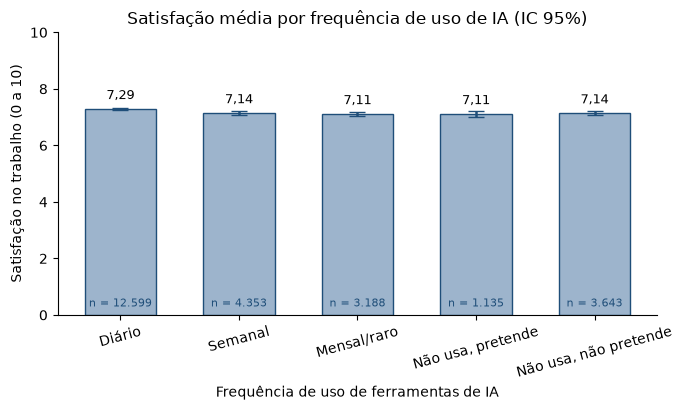

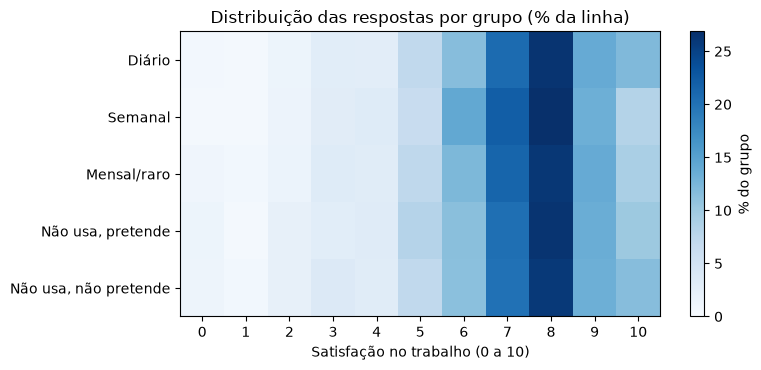

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.2))
xs = np.arange(len(ORDEM))
medias = descritiva.loc[ORDEM, 'média']
err = [medias - descritiva.loc[ORDEM, 'IC95% inf'], descritiva.loc[ORDEM, 'IC95% sup'] - medias]
ax.bar(xs, medias, color='#9db4cc', edgecolor='#1f4e79', width=0.6)
ax.errorbar(xs, medias, yerr=err, fmt='none', ecolor='#1f4e79', capsize=6, linewidth=1.8)
for i, (m, n) in enumerate(zip(medias, descritiva.loc[ORDEM, 'n'])):
    ax.text(i, 0.3, f'n = {n:,}'.replace(',', '.'), ha='center', fontsize=8, color='#1f4e79')
    ax.text(i, m + 0.35, f'{m:.2f}'.replace('.', ','), ha='center', fontsize=9)
ax.set_xticks(xs, ORDEM, rotation=15)
ax.set_ylim(0, 10)
ax.set_ylabel('Satisfação no trabalho (0 a 10)')
ax.set_xlabel('Frequência de uso de ferramentas de IA')
ax.set_title('Satisfação média por frequência de uso de IA (IC 95%)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / 'fig1_satisfacao_por_grupo.png', dpi=300)
plt.show()

dist = (pd.crosstab(amostra['grupo_ia'], amostra['JobSat'], normalize='index') * 100).loc[ORDEM]
fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(dist.values, aspect='auto', cmap='Blues', vmin=0)
ax.set_yticks(range(len(ORDEM)), ORDEM)
ax.set_xticks(range(dist.shape[1]), [str(int(c)) for c in dist.columns])
ax.set_xlabel('Satisfação no trabalho (0 a 10)')
ax.set_title('Distribuição das respostas por grupo (% da linha)')
fig.colorbar(im, ax=ax, label='% do grupo')
fig.tight_layout()
fig.savefig(FIGURAS / 'fig2_distribuicao_por_grupo.png', dpi=300)
plt.show()

## 5. Pressupostos da ANOVA de um fator

A ANOVA supõe variâncias iguais entre os grupos e resíduos aproximadamente normais. Regra do protocolo: se o teste de **Levene** der p < 0,05 **ou** os resíduos se afastarem claramente da normalidade (inspeção do Q-Q plot; com n grande, testes formais de normalidade rejeitam qualquer desvio mínimo), o teste principal passa a ser o **Kruskal-Wallis**.

A escala de satisfação é **ordinal** (0 a 10, valores inteiros), o que também favorece o teste não paramétrico.

Levene (centro = mediana): W = 8.44, p = 8.48e-07
Resíduos: assimetria = -1.02, curtose (excesso) = 1.30


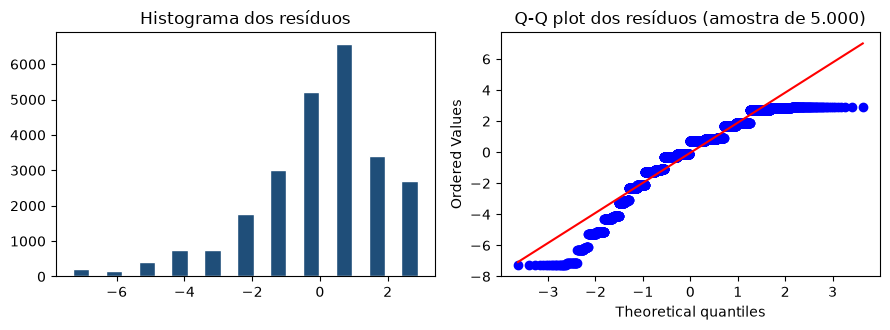

Teste principal: Kruskal-Wallis


In [7]:
amostras = [amostra.loc[amostra['grupo_ia'] == g, 'JobSat'].to_numpy(float) for g in ORDEM]
levene = stats.levene(*amostras, center='median')
print(f'Levene (centro = mediana): W = {levene.statistic:.2f}, p = {levene.pvalue:.3g}')

residuos = np.concatenate([a - a.mean() for a in amostras])
assimetria, curtose = stats.skew(residuos), stats.kurtosis(residuos)
print(f'Resíduos: assimetria = {assimetria:.2f}, curtose (excesso) = {curtose:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(residuos, bins=21, color='#1f4e79', edgecolor='white')
axes[0].set_title('Histograma dos resíduos')
rng = np.random.default_rng(2026)
amostra_qq = rng.choice(residuos, size=min(5000, len(residuos)), replace=False)
stats.probplot(amostra_qq, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot dos resíduos (amostra de 5.000)')
fig.tight_layout()
fig.savefig(FIGURAS / 'fig3_pressupostos.png', dpi=300)
plt.show()

usar_kruskal = (levene.pvalue < ALFA) or (abs(assimetria) > 1)
print('Teste principal:', 'Kruskal-Wallis' if usar_kruskal else 'ANOVA de um fator')

## 6. Teste confirmatório

**H0:** a satisfação no trabalho tem a mesma distribuição (mesma média/mediana) nos 5 grupos de uso de IA.
**H1:** pelo menos um grupo difere.

Reportamos os dois testes por transparência, mas a **decisão** usa o teste definido na seção 5. Tamanhos de efeito: η² (ANOVA) e ε² (Kruskal-Wallis).

In [8]:
N, k = len(amostra), len(ORDEM)

anova = stats.f_oneway(*amostras)
media_geral = amostra['JobSat'].mean()
sq_entre = sum(len(a) * (a.mean() - media_geral) ** 2 for a in amostras)
sq_total = ((amostra['JobSat'] - media_geral) ** 2).sum()
eta2 = sq_entre / sq_total

kw = stats.kruskal(*amostras)
eps2 = (kw.statistic - k + 1) / (N - k)

print(f'ANOVA de um fator: F({k - 1}, {N - k}) = {anova.statistic:.2f}, p = {anova.pvalue:.3g}, η² = {eta2:.4f}')
print(f'Kruskal-Wallis: H({k - 1}) = {kw.statistic:.2f}, p = {kw.pvalue:.3g}, ε² = {eps2:.4f}')

teste = 'Kruskal-Wallis' if usar_kruskal else 'ANOVA de um fator'
p_decisao = kw.pvalue if usar_kruskal else anova.pvalue
efeito = eps2 if usar_kruskal else eta2
decisao = 'rejeita H0' if p_decisao < ALFA else 'não rejeita H0'
print(f'\nDecisão ({teste}, α = {ALFA}): p = {p_decisao:.3g} → {decisao}')
print(f'Tamanho de efeito: {efeito:.4f} ({efeito * 100:.2f}% da variação explicada pelo grupo)')

ANOVA de um fator: F(4, 24913) = 10.26, p = 2.68e-08, η² = 0.0016
Kruskal-Wallis: H(4) = 40.23, p = 3.89e-08, ε² = 0.0015

Decisão (Kruskal-Wallis, α = 0.05): p = 3.89e-08 → rejeita H0
Tamanho de efeito: 0.0015 (0.15% da variação explicada pelo grupo)


### 6.1 Comparações par a par (somente se H0 for rejeitada)

Para saber **quais** grupos diferem: Mann-Whitney para cada par (ou Tukey HSD, se o teste principal for a ANOVA), com **correção de Bonferroni** para os 10 pares. Efeito de cada par: diferença de médias e correlação bisserial de postos *r*.

In [9]:
pares = []
if p_decisao < ALFA:
    n_pares = k * (k - 1) // 2
    for (i, a), (j, b) in combinations(enumerate(ORDEM), 2):
        xa, xb = amostras[i], amostras[j]
        mw = stats.mannwhitneyu(xa, xb, alternative='two-sided')
        r = 1 - 2 * mw.statistic / (len(xa) * len(xb))
        pares.append({'grupo A': a, 'grupo B': b, 'dif. médias (A − B)': xa.mean() - xb.mean(),
                      'r (bisserial)': -r, 'p bruto': mw.pvalue, 'p Bonferroni': min(1.0, mw.pvalue * n_pares)})
    pares = pd.DataFrame(pares)
    pares['significativo'] = pares['p Bonferroni'] < ALFA
    if not usar_kruskal:
        tukey = stats.tukey_hsd(*amostras)
        print(tukey)
    pares.to_csv(LIMPOS / 'comparacoes_par_a_par.csv', index=False)
    display(pares.round(4))
else:
    print('H0 não rejeitada: comparações par a par não são feitas.')

resultado = pd.Series({'n_total': N, 'k_grupos': k, 'levene_p': levene.pvalue,
                       'anova_F': anova.statistic, 'anova_p': anova.pvalue, 'eta2': eta2,
                       'kruskal_H': kw.statistic, 'kruskal_p': kw.pvalue, 'epsilon2': eps2,
                       'teste_decisao': teste, 'decisao': decisao})
resultado.to_csv(LIMPOS / 'resultado_confirmatorio.csv', header=['valor'])

,grupo A,grupo B,dif. médias (A − B),r (bisserial),p bruto,p Bonferroni,significativo
0,Diário,Semanal,1.467e-01,0.053,0.000,0.000e+00,True
1,Diário,Mensal/raro,1.801e-01,0.048,0.000,2.000e-04,True
2,Diário,"Não usa, pretende",1.794e-01,0.042,0.018,1.838e-01,False
3,Diário,"Não usa, não pretende",1.515e-01,0.029,0.008,7.560e-02,False
4,Semanal,Mensal/raro,3.340e-02,-0.004,0.752,1.000e+00,False
5,Semanal,"Não usa, pretende",3.280e-02,-0.010,0.586,1.000e+00,False
6,Semanal,"Não usa, não pretende",4.800e-03,-0.023,0.072,7.180e-01,False
7,Mensal/raro,"Não usa, pretende",-7.000e-04,-0.006,0.753,1.000e+00,False
8,Mensal/raro,"Não usa, não pretende",-2.860e-02,-0.019,0.175,1.000e+00,False
9,"Não usa, pretende","Não usa, não pretende",-2.790e-02,-0.012,0.520,1.000e+00,False


**Como interpretar:** com dezenas de milhares de respondentes, até diferenças minúsculas dão p-valor muito pequeno. Por isso a discussão deve se apoiar no **tamanho de efeito** (η² ou ε²; referência usual: 0,01 pequeno, 0,06 médio, 0,14 grande) e na diferença de médias em pontos da escala 0–10, não só no p-valor.

> Escrevam a interpretação no artigo **depois** de ver estes números, sem trocar teste, α ou VD.

## 7. Análises exploratórias (fora do protocolo confirmatório)

Esta seção **não testa hipóteses**. Ela só descreve padrões para discussão e próximos passos, e no artigo deve aparecer numa subseção chamada **“Análises exploratórias”**.

### 7.1 Recorte Brasil

In [10]:
br = amostra[amostra['Country'] == 'Brazil']
print('Respondentes do Brasil na amostra:', len(br))
br.groupby('grupo_ia', observed=False)['JobSat'].agg(['count', 'mean', 'std', 'median']).round(2)

Respondentes do Brasil na amostra: 607


,count,mean,std,median
grupo_ia,,,,
Diário,359,7.37,2.06,8.0
Semanal,108,7.44,1.77,8.0
Mensal/raro,72,7.26,2.40,8.0
"Não usa, pretende",16,7.50,2.28,8.0
"Não usa, não pretende",52,7.48,2.37,8.0


### 7.2 Por tempo de experiência profissional (`WorkExp`, em anos)

In [11]:
if 'WorkExp' in amostra:
    faixas = pd.cut(pd.to_numeric(amostra['WorkExp'], errors='coerce'), [-0.1, 5, 15, 100],
                    labels=['0–5 anos', '6–15 anos', '16+ anos'])
    tab = amostra.groupby([faixas, 'grupo_ia'], observed=False)['JobSat'].mean().unstack().round(2)
    display(tab)

grupo_ia,Diário,Semanal,Mensal/raro,"Não usa, pretende","Não usa, não pretende"
WorkExp,,,,,
0–5 anos,6.95,6.92,6.97,6.73,6.97
6–15 anos,7.31,7.12,6.97,7.06,6.99
16+ anos,7.58,7.36,7.36,7.29,7.36


### 7.3 Sentimento em relação às ferramentas de IA (`AISent`)

In [12]:
if 'AISent' in amostra:
    display(amostra.groupby('AISent')['JobSat'].agg(['count', 'mean', 'median']).sort_values('mean').round(2))

,count,mean,median
AISent,,,
Unsure,428,6.90,7.0
Very unfavorable,2221,6.91,7.0
Unfavorable,2635,7.08,7.0
Indifferent,4307,7.12,7.0
Favorable,9330,7.23,8.0
Very favorable,5819,7.45,8.0


---
### Versões usadas

In [13]:
import sys, scipy, matplotlib
print('Python', sys.version.split()[0])
print('pandas', pd.__version__, '| numpy', np.__version__, '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.5
pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | matplotlib 3.11.2
